# 一、支持向量机

In [2]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.linear_model import Perceptron
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

# 自实现模型（models/exp2/）
sys.path.insert(0, ".")
from models.exp2.svm import SVC as MySVC
from models.exp2.perceptron import Perceptron as MyPerceptron


/home/yukari/PycharmProjects/machine_learning/.venv/lib/python3.12/site-packages/joblib/_multiprocessing_helpers.py:44: UserWarning: [Errno 13] Permission denied.  joblib will operate in serial mode
  warnings.warn("%s.  joblib will operate in serial mode" % (e,))


## a.编写Python代码实现支持向量机

In [3]:
# 还可以选择kernel = 'linear'或者'poly'
svm_model = SVC(kernel="rbf", C=1.0, gamma="scale")

## b.加载数据集后，进行基本的数据清洗和处理

In [4]:
df = pd.read_csv("data/exp2/auto-mpg.data", sep=r"\s+",
    names=["mpg","cylinders","displacement",
        "horsepower","weight","acceleration",
        "model_year","origin","car_name"],
    na_values="?")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    str    
dtypes: float64(5), int64(3), str(1)
memory usage: 28.1 KB


In [5]:
# 由于horsepower字段有缺失，将其删除
df = df.dropna()

In [6]:
df["grade"] = (df["mpg"] >= df["mpg"].median()).astype(int)
print(df["grade"].value_counts())

grade
0    196
1    196
Name: count, dtype: int64


## c.将数据集分为训练集和测试集，使用支持向量机模型进行训练，选择合适的核函数如RBF核函数。（可以尝试使用其他核函数）

In [7]:
X = df[["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year", "origin"]]
y = df["grade"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [8]:
# SVM 对特征的尺度比较敏感，故进行标准化
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [9]:
svm_model.fit(X_train_scaled, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


## d.在测试集上进行预测，并计算模型的准确率、混淆矩阵、精确率等指标

In [10]:
y_pred = svm_model.predict(X_test_scaled)

In [11]:
accuracy = accuracy_score(y_test, y_pred)
print("模型准确率：{:.2f}%".format(accuracy * 100))

模型准确率：89.87%


In [12]:
cm = confusion_matrix(y_test, y_pred)

print("\n混淆矩阵：")
print(cm)


混淆矩阵：
[[34  6]
 [ 2 37]]


In [13]:
report = classification_report(y_test, y_pred, target_names=["低MPG", "高MPG"])
print(report)

              precision    recall  f1-score   support

        低MPG       0.94      0.85      0.89        40
        高MPG       0.86      0.95      0.90        39

    accuracy                           0.90        79
   macro avg       0.90      0.90      0.90        79
weighted avg       0.90      0.90      0.90        79



In [14]:
# 自实现 SVM（SMO 求解对偶问题）
my_svm = MySVC(kernel="rbf", C=1.0, gamma="scale", tol=1e-3, max_iter=5000)
my_svm.fit(X_train_scaled, y_train)
my_svm_pred = my_svm.predict(X_test_scaled)

svm_comparison = pd.DataFrame({
    "实现方式": ["sklearn 调包", "自实现 (SMO)"],
    "准确率(%)": [accuracy * 100, accuracy_score(y_test, my_svm_pred) * 100],
    "支持向量数": [int(svm_model.n_support_.sum()), int(my_svm.n_support_.sum())],
})
print("两种 SVM 实现的结果对比：")
print(svm_comparison.to_string(index=False))
print("\n两种实现的预测一致率：{:.2%}".format((my_svm_pred == y_pred).mean()))


两种 SVM 实现的结果对比：
      实现方式    准确率(%)  支持向量数
sklearn 调包 89.873418     89
 自实现 (SMO) 89.873418     89

两种实现的预测一致率：100.00%


## e.绘制分类结果的混淆矩阵图

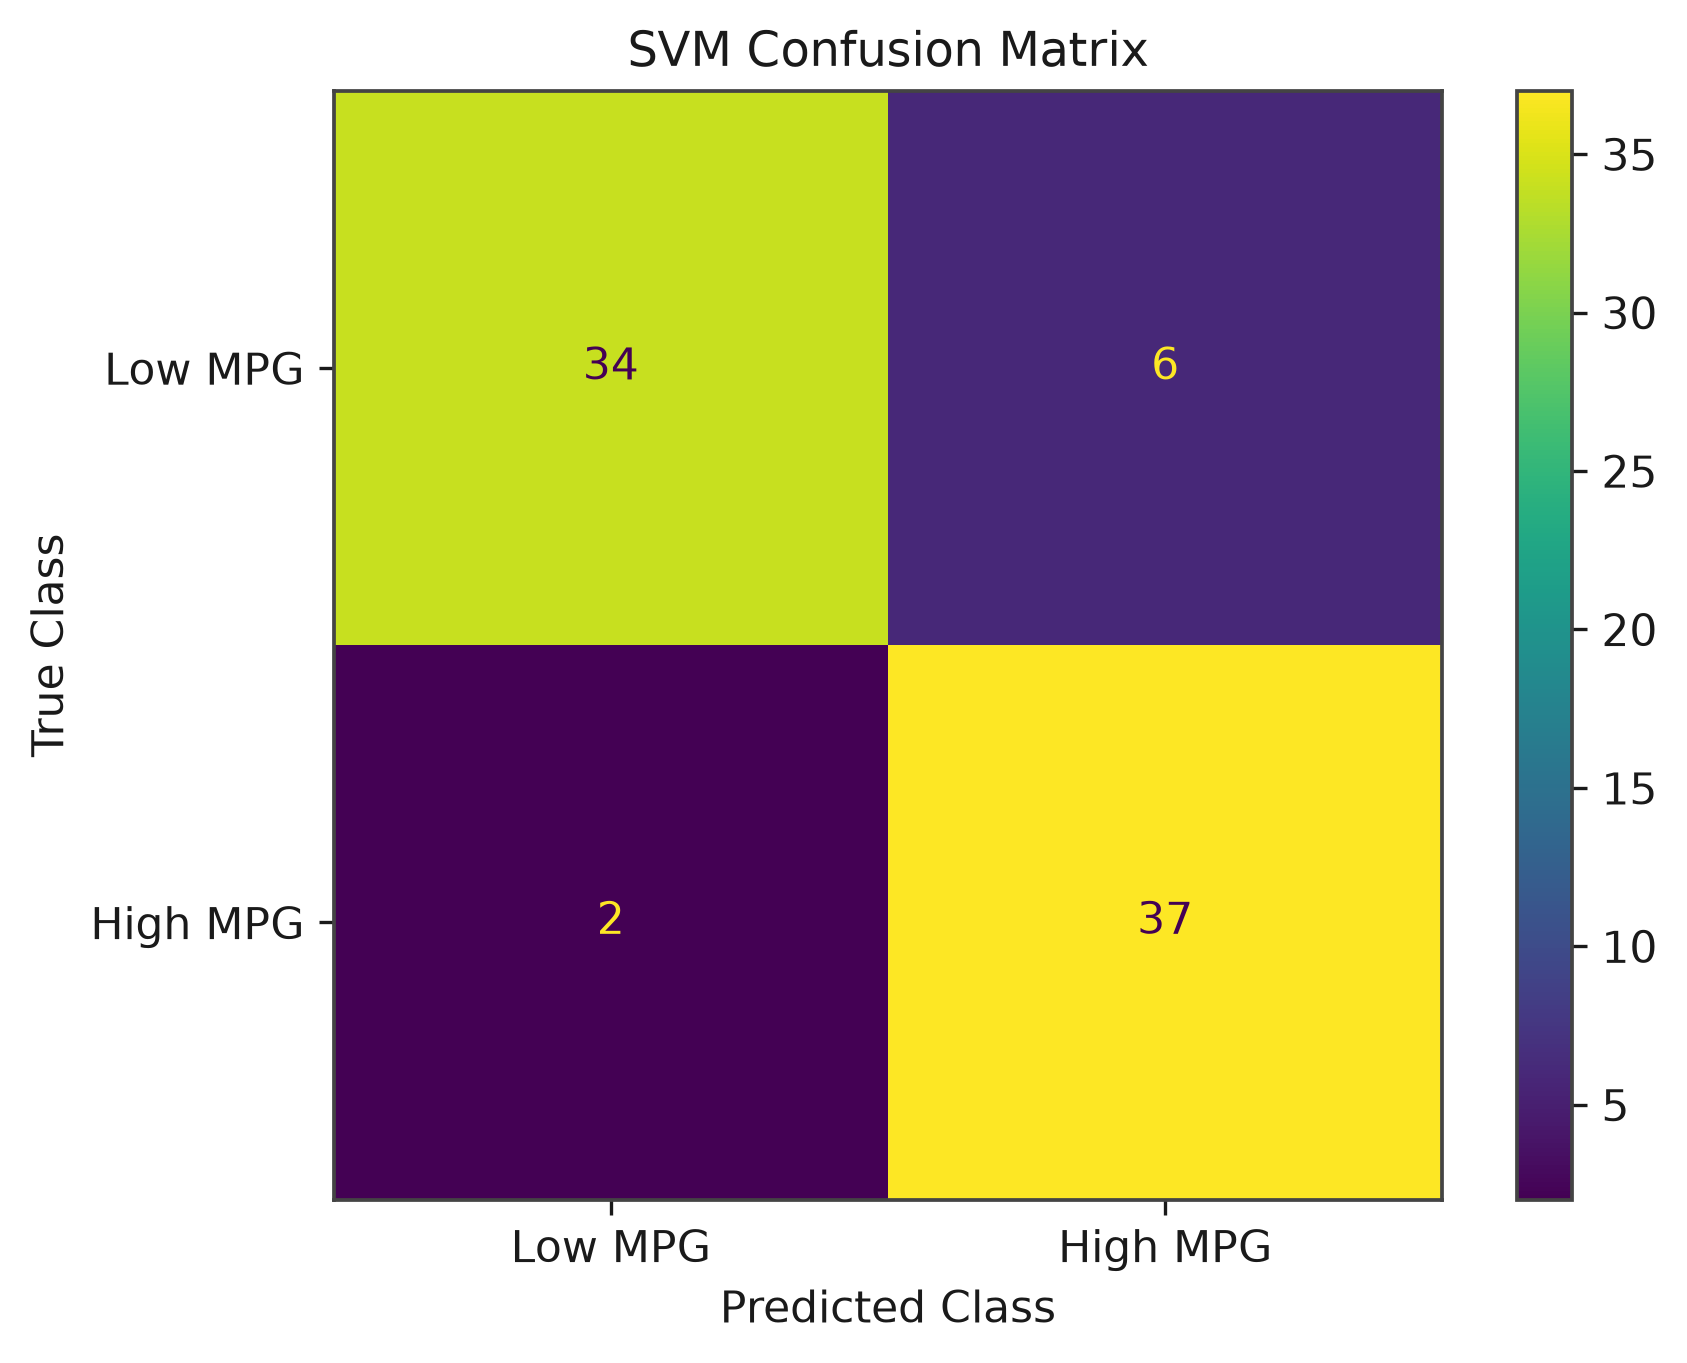

In [15]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Low MPG", "High MPG"])
disp.plot()
plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.show()

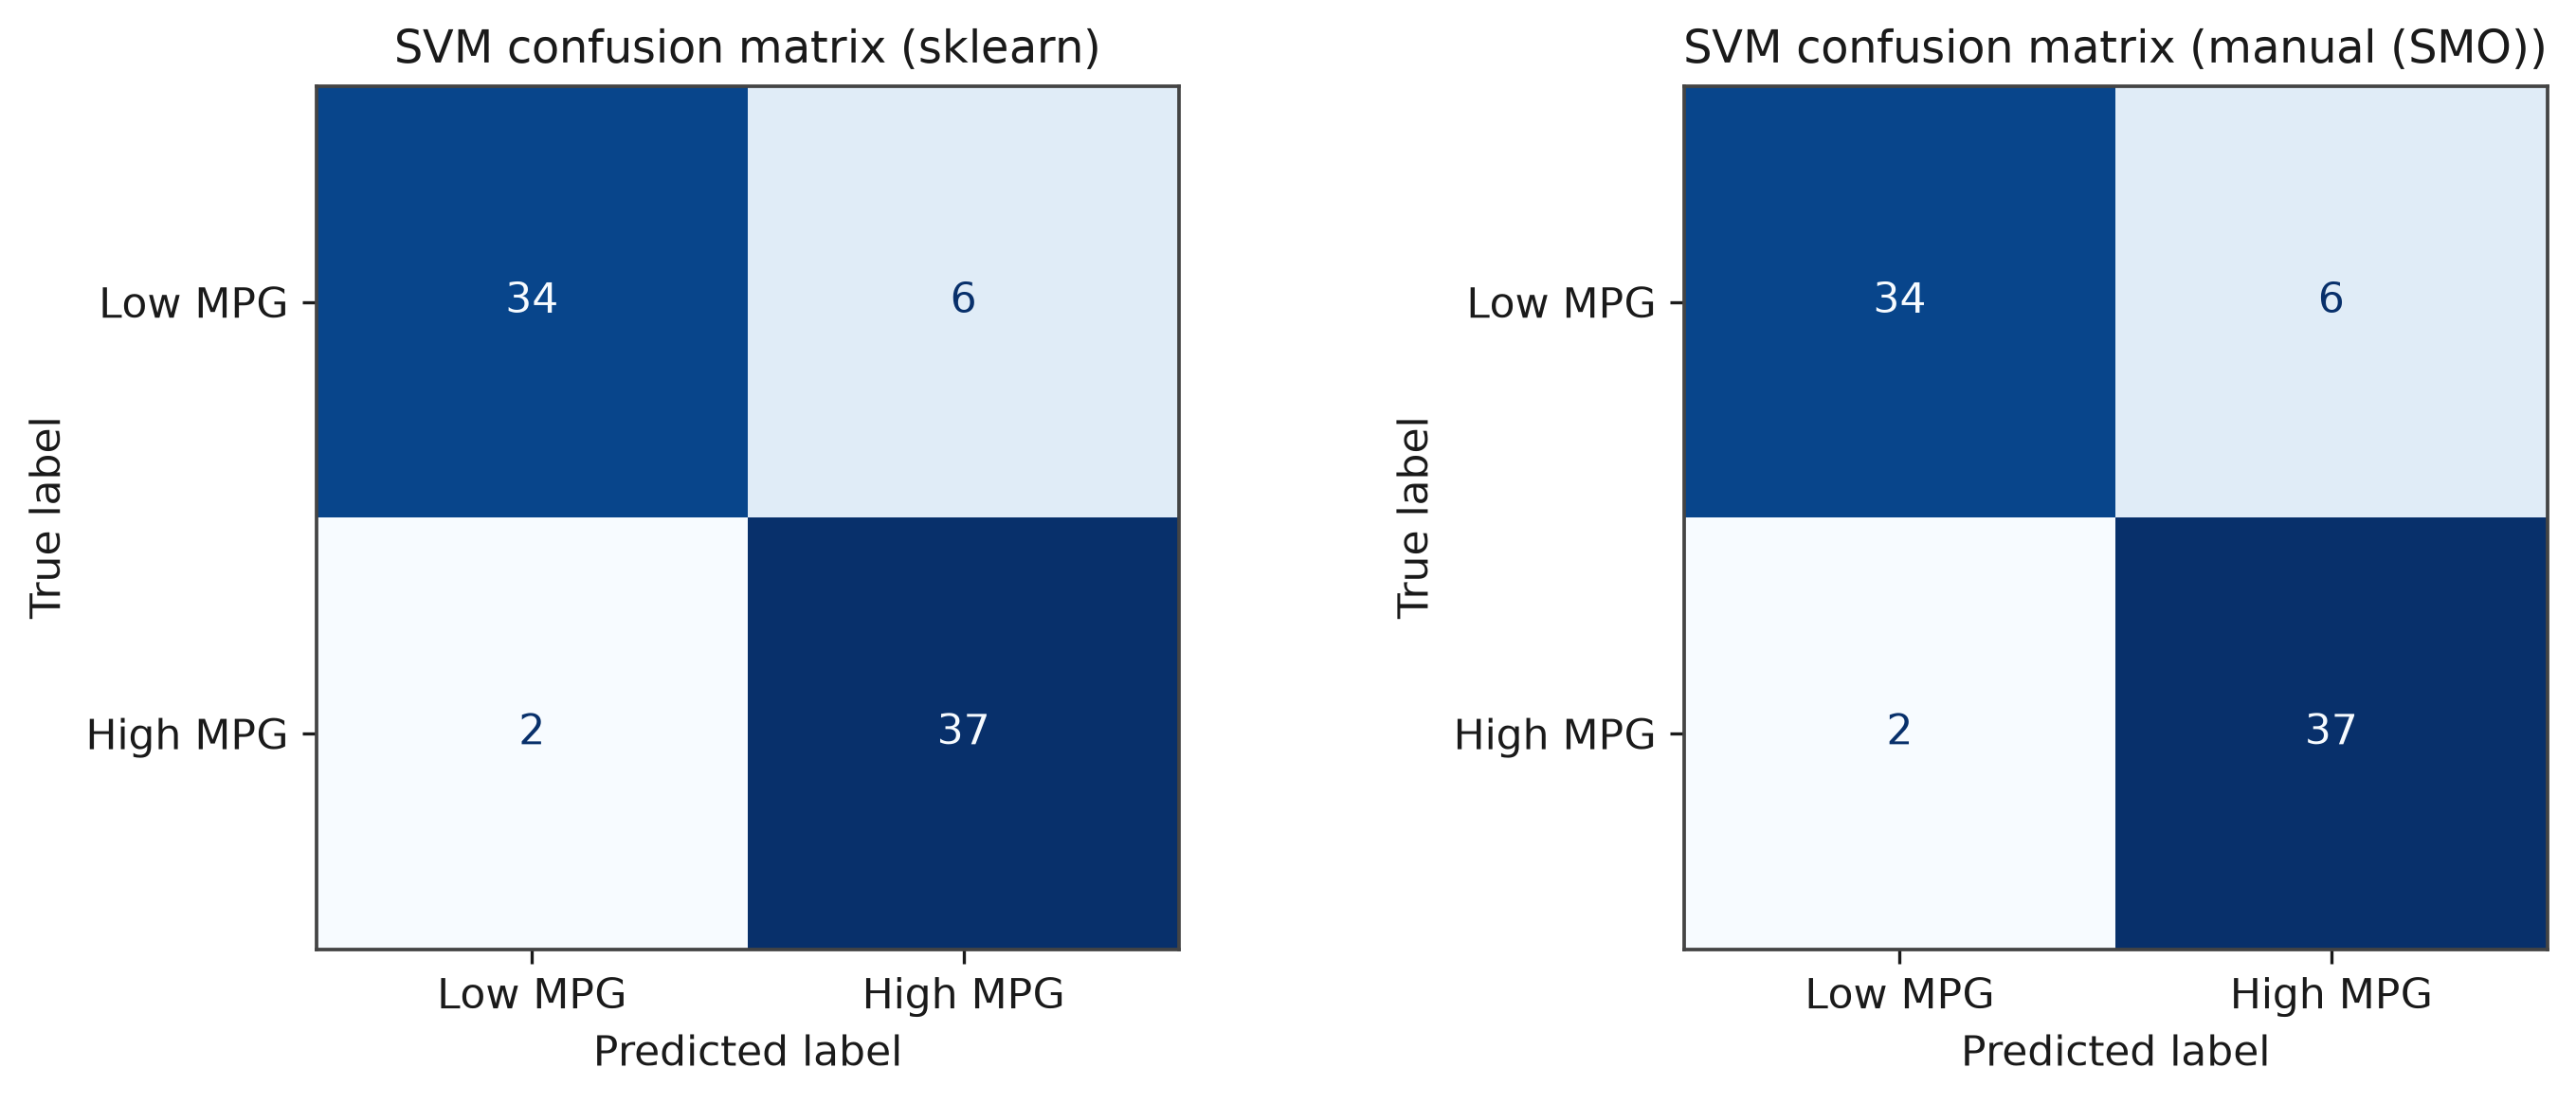

In [16]:
# 两种 SVM 实现的混淆矩阵对比
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (cm_show, title) in zip(axes, [(cm, "sklearn"), (confusion_matrix(y_test, my_svm_pred), "manual (SMO)")]):
    ConfusionMatrixDisplay(confusion_matrix=cm_show, display_labels=["Low MPG", "High MPG"]).plot(
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title("SVM confusion matrix ({})".format(title))
plt.tight_layout()
plt.show()


# 二、感知机

In [17]:
df = pd.read_csv('data/exp2/diabetes.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


## a.编写Python代码实现感知机模型

In [18]:
perceptron = Perceptron(
    max_iter=1000,
    tol=1e-3,
    random_state=42
)

## b.实现数据的预处理，使用感知机模型进行糖尿病数据的分类

In [19]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y)

In [20]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [21]:
perceptron.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",1.0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None


In [22]:
y_pred = perceptron.predict(X_test_scaled)

## c.输出模型的准确率、混淆矩阵

In [23]:
accuracy = accuracy_score(y_test, y_pred)
print("\n模型准确率：{:.2f}%".format(accuracy * 100))


模型准确率：72.73%


In [24]:
cm = confusion_matrix(y_test, y_pred)
print("\n混淆矩阵：")
print(cm)


混淆矩阵：
[[80 20]
 [22 32]]


In [25]:
report = classification_report(y_test, y_pred, target_names=["未患糖尿病", "患糖尿病"])
print(report)

              precision    recall  f1-score   support

       未患糖尿病       0.78      0.80      0.79       100
        患糖尿病       0.62      0.59      0.60        54

    accuracy                           0.73       154
   macro avg       0.70      0.70      0.70       154
weighted avg       0.73      0.73      0.73       154



In [26]:
# 自实现感知机
my_perceptron = MyPerceptron(max_iter=1000, tol=1e-3, random_state=42)
my_perceptron.fit(X_train_scaled, y_train)
my_perc_pred = my_perceptron.predict(X_test_scaled)

perc_comparison = pd.DataFrame({
    "实现方式": ["sklearn 调包", "自实现"],
    "准确率(%)": [accuracy * 100, accuracy_score(y_test, my_perc_pred) * 100],
    "迭代轮数": [perceptron.n_iter_, my_perceptron.n_iter_],
})
print("两种感知机实现的结果对比：")
print(perc_comparison.to_string(index=False))
print("\n两种实现的预测一致率：{:.2%}".format((my_perc_pred == y_pred).mean()))
print("两种实现的权重相关系数：{:.4f}".format(
    np.corrcoef(perceptron.coef_[0], my_perceptron.coef_[0])[0, 1]))


两种感知机实现的结果对比：
      实现方式    准确率(%)  迭代轮数
sklearn 调包 72.727273     6
       自实现 68.831169     7

两种实现的预测一致率：79.22%
两种实现的权重相关系数：0.6633


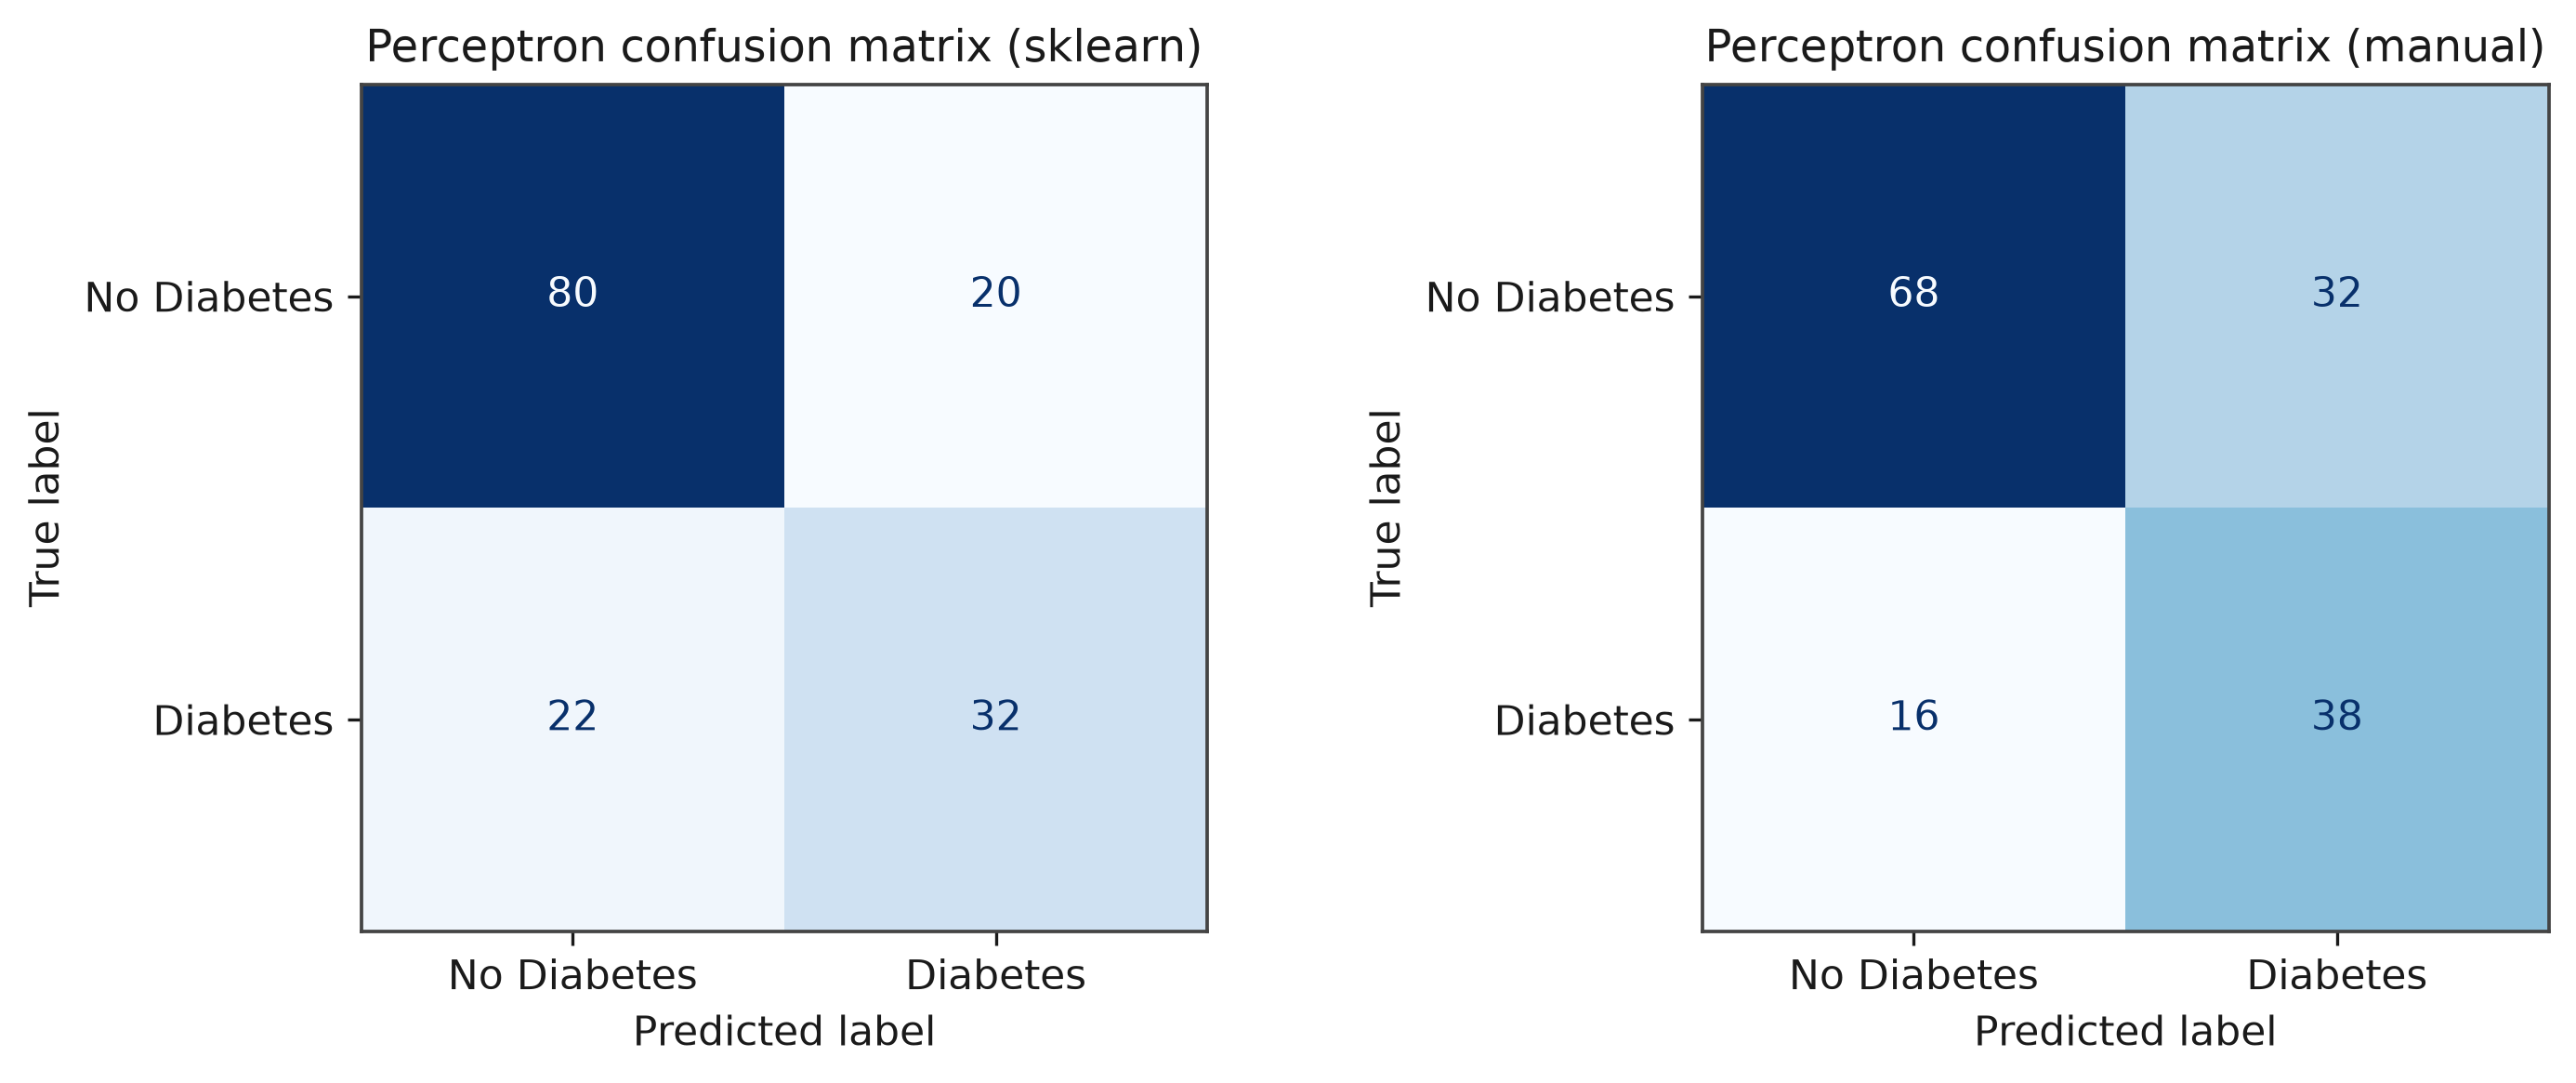

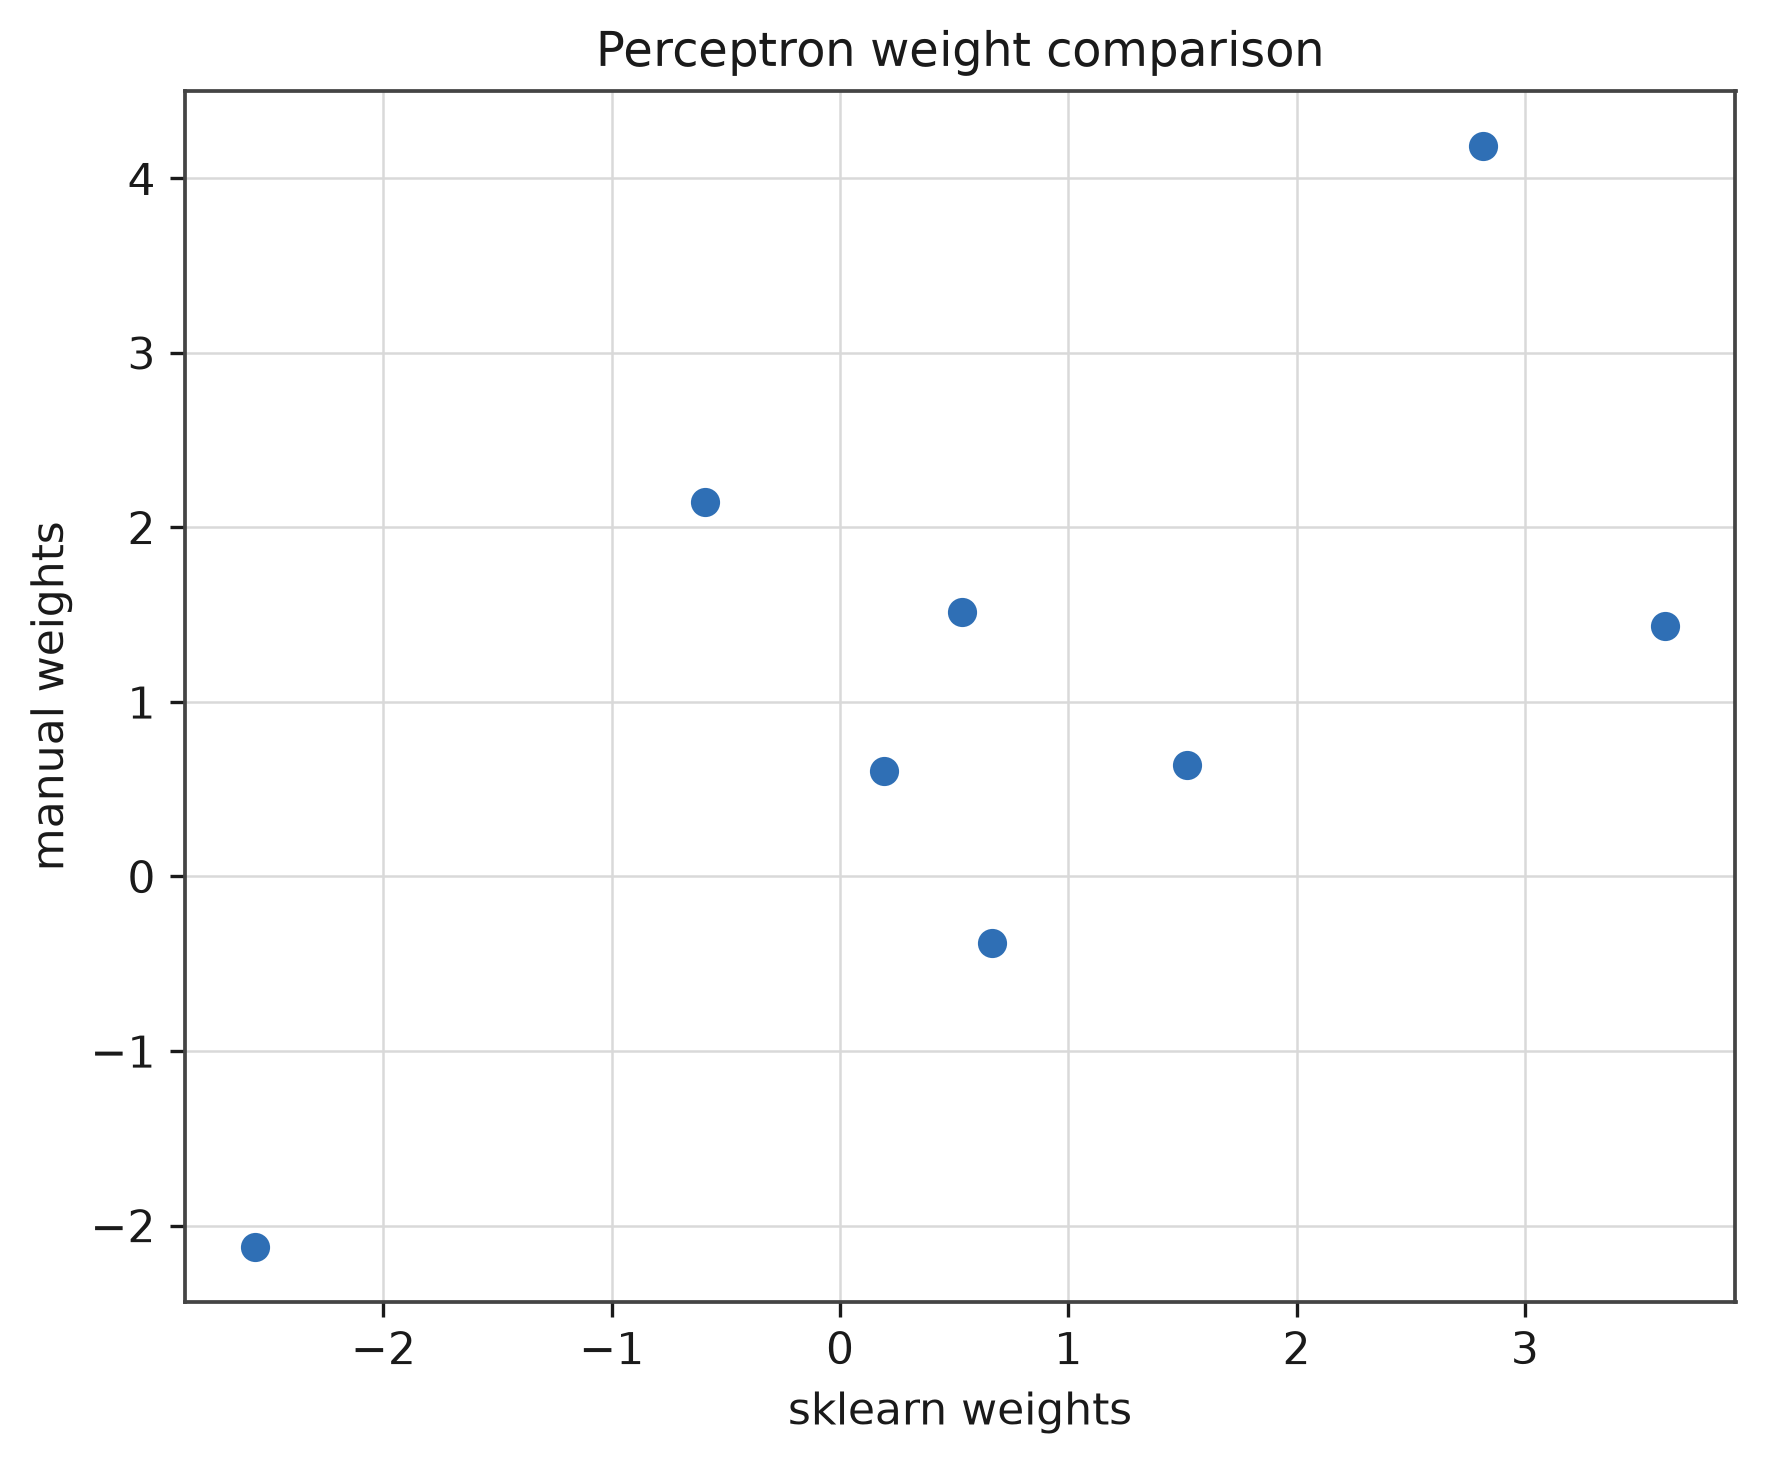

In [27]:
# 混淆矩阵与权重的对比
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (cm_show, title) in zip(axes, [(cm, "sklearn"), (confusion_matrix(y_test, my_perc_pred), "manual")]):
    ConfusionMatrixDisplay(confusion_matrix=cm_show,
                           display_labels=["No Diabetes", "Diabetes"]).plot(
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title("Perceptron confusion matrix ({})".format(title))
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
plt.scatter(perceptron.coef_[0], my_perceptron.coef_[0])
plt.xlabel("sklearn weights")
plt.ylabel("manual weights")
plt.title("Perceptron weight comparison")
plt.grid(True)
plt.tight_layout()
plt.show()


## d.可视化特征权重，以分析模型性能和特征重要性

In [28]:
feature_importance = pd.DataFrame({"Feature": X.columns, "Weight": perceptron.coef_[0]})
feature_importance["AbsWeight"] = feature_importance["Weight"].abs()
feature_importance = feature_importance.sort_values("AbsWeight", ascending=True)

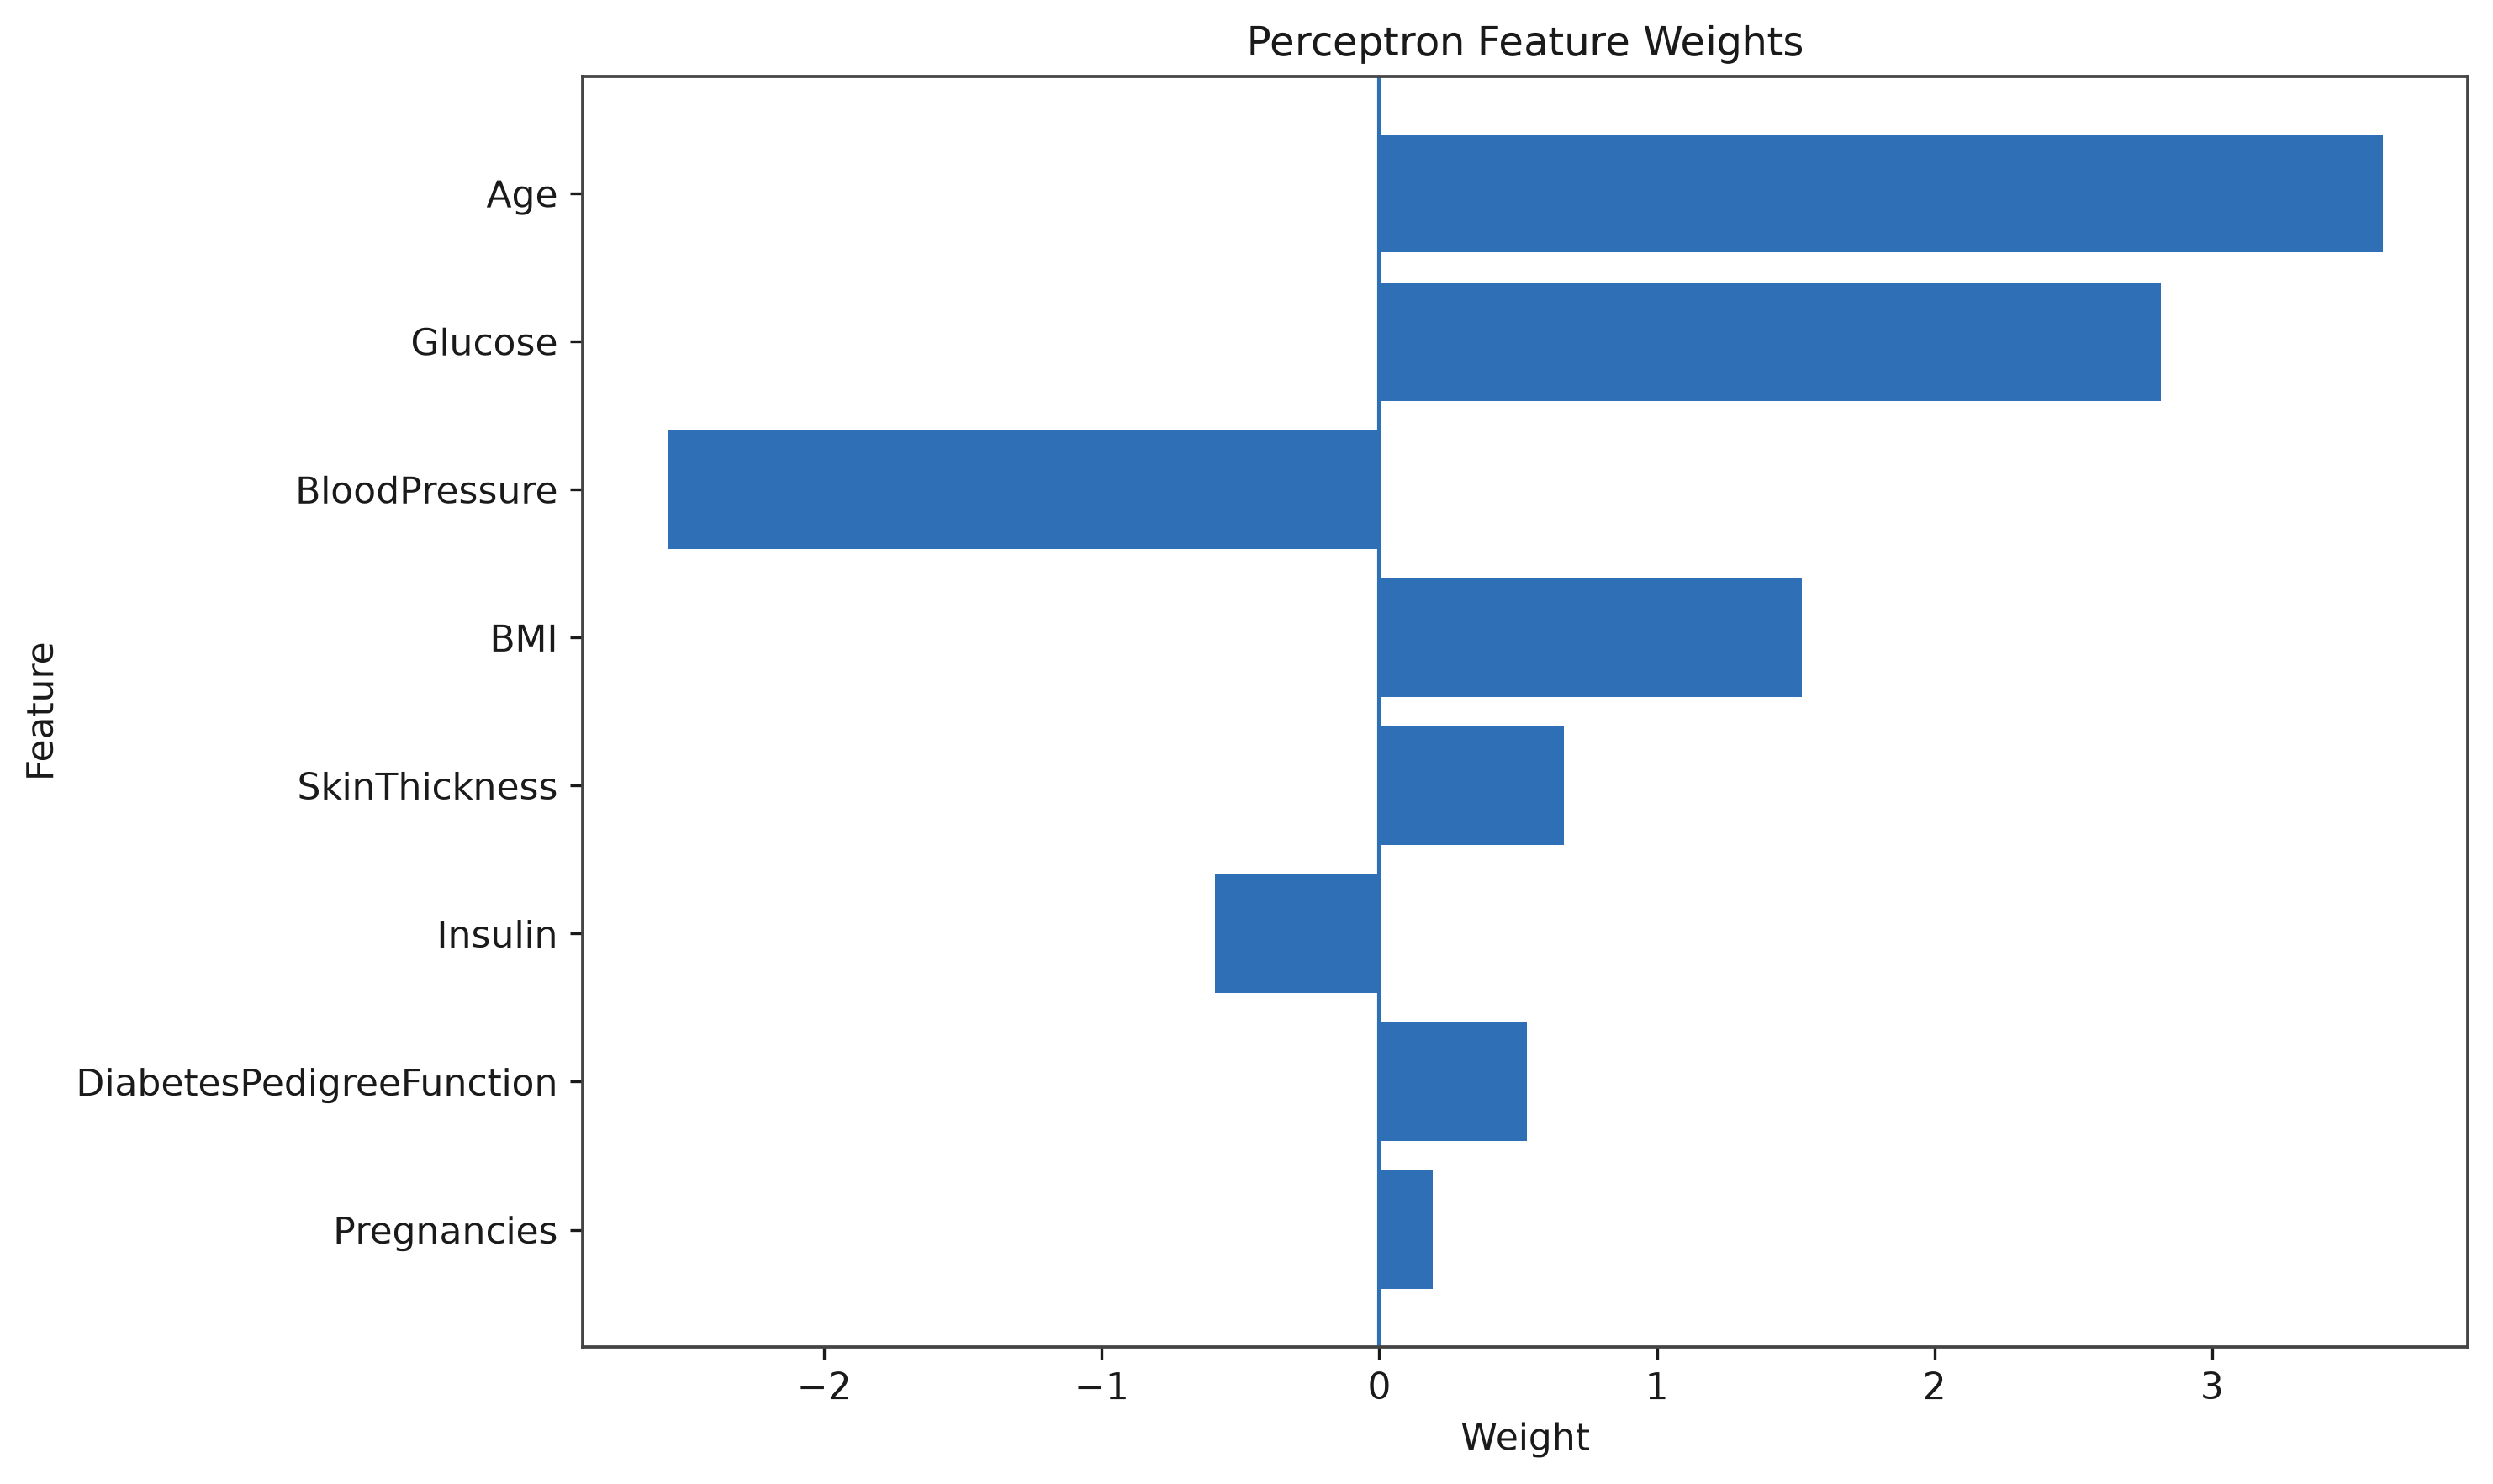

In [29]:
plt.figure(figsize=(10, 6))
plt.barh(feature_importance["Feature"],feature_importance["Weight"])
plt.xlabel("Weight")
plt.ylabel("Feature")
plt.title("Perceptron Feature Weights")
plt.axvline(x=0, linewidth=1)
plt.tight_layout()
plt.show()